<a href="https://colab.research.google.com/github/vamsi-krishna09/Machine_Learning_Projects/blob/main/CNN_diesase_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/pratikkayal/PlantDoc-Dataset.git

Cloning into 'PlantDoc-Dataset'...
remote: Enumerating objects: 2670, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 2670 (delta 22), reused 22 (delta 22), pack-reused 2635 (from 1)
Receiving objects: 100% (2670/2670), 932.92 MiB | 29.87 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Updating files: 100% (2581/2581), done.


In [ ]:
!ls PlantDoc-Dataset

LICENSE.txt  PlantDoc_Examples.png  README.md  test  train


In [ ]:
!ls PlantDoc-Dataset/train


'Apple leaf'		    'Potato leaf late blight'
'Apple rust leaf'	    'Raspberry leaf'
'Apple Scab Leaf'	    'Soyabean leaf'
'Bell_pepper leaf'	    'Squash Powdery mildew leaf'
'Bell_pepper leaf spot'     'Strawberry leaf'
'Blueberry leaf'	    'Tomato Early blight leaf'
'Cherry leaf'		    'Tomato leaf'
'Corn Gray leaf spot'	    'Tomato leaf bacterial spot'
'Corn leaf blight'	    'Tomato leaf late blight'
'Corn rust leaf'	    'Tomato leaf mosaic virus'
'grape leaf'		    'Tomato leaf yellow virus'
'grape leaf black rot'	    'Tomato mold leaf'
'Peach leaf'		    'Tomato Septoria leaf spot'
'Potato leaf early blight'  'Tomato two spotted spider mites leaf'


In [ ]:
import os
train_dir="PlantDoc-Dataset/train"
for class_name in os.listdir(train_dir):
  class_path=os.path.join(train_dir,class_name)
  if os.path.isdir(class_path):
    count=len(os.listdir(class_path))
    print(f"{class_name}:{count}images")


Soyabean leaf:57images
Tomato leaf:55images
Potato leaf late blight:97images
Corn leaf blight:180images
Apple rust leaf:79images
Corn rust leaf:106images
Peach leaf:103images
Corn Gray leaf spot:64images
Bell_pepper leaf:53images
Tomato mold leaf:85images
Bell_pepper leaf spot:62images
Tomato Early blight leaf:79images
Tomato leaf bacterial spot:101images
Squash Powdery mildew leaf:124images
Tomato two spotted spider mites leaf:2images
Tomato leaf yellow virus:70images
Cherry leaf:47images
Tomato leaf mosaic virus:44images
Tomato Septoria leaf spot:140images
Blueberry leaf:106images
Potato leaf early blight:109images
Apple Scab Leaf:83images
Raspberry leaf:112images
Strawberry leaf:88images
grape leaf black rot:56images
Apple leaf:82images
grape leaf:57images
Tomato leaf late blight:101images


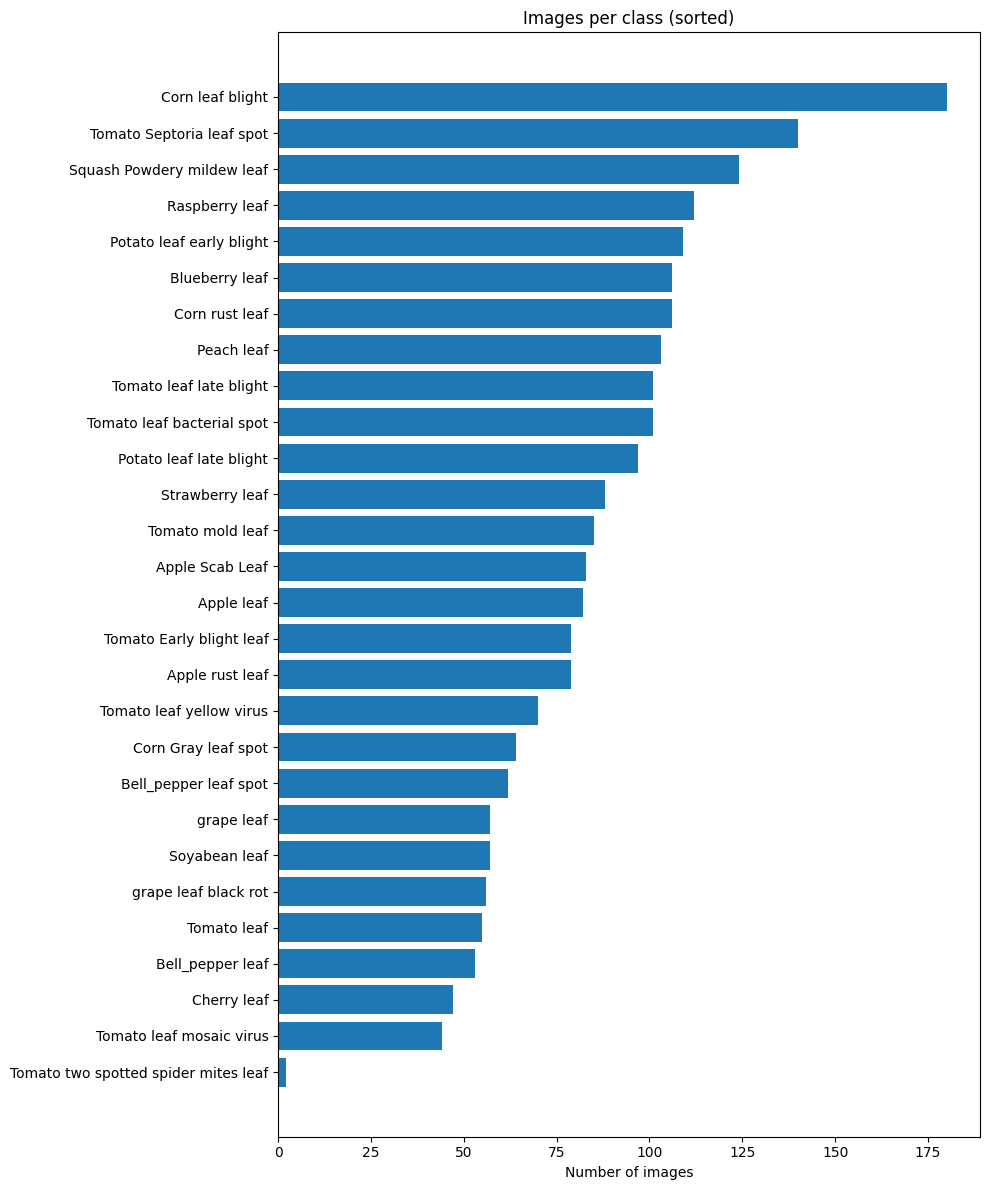

In [ ]:
import matplotlib.pyplot as plt

class_counts = {}
for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)
    if os.path.isdir(class_path):
        class_counts[class_name] = len(os.listdir(class_path))

# sort smallest to largest - problem classes show up first
sorted_counts = dict(sorted(class_counts.items(), key=lambda x: x[1]))

plt.figure(figsize=(10, 12))
plt.barh(list(sorted_counts.keys()), list(sorted_counts.values()))
plt.xlabel("Number of images")
plt.title("Images per class (sorted)")
plt.tight_layout()
plt.show()

In [ ]:
corrupt_files = []

for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)
    if not os.path.isdir(class_path):
        continue
    for img_name in os.listdir(class_path):
        img_path = os.path.join(class_path, img_name)
        try:
            img = Image.open(img_path)
            img.verify()  # checks the file is a valid, uncorrupted image
        except Exception as e:
            corrupt_files.append(img_path)

print(f"Found {len(corrupt_files)} corrupt/unreadable images:")
for f in corrupt_files:
    print(" ", f)

Found 2342 corrupt/unreadable images:
  PlantDoc-Dataset/train/Soyabean leaf/Soybean%20oil%20leaf2.JPG.jpg
  PlantDoc-Dataset/train/Soyabean leaf/KDeficientSoyBean.jpg
  PlantDoc-Dataset/train/Soyabean leaf/soybean-potassium-deficiency-2.jpg
  PlantDoc-Dataset/train/Soyabean leaf/soybean-leaf-single.jpg
  PlantDoc-Dataset/train/Soyabean leaf/stock-photo-soybean-on-the-pod-with-leaves-for-healthy-eating-concept-62173117.jpg
  PlantDoc-Dataset/train/Soyabean leaf/kdeficiency4.jpg
  PlantDoc-Dataset/train/Soyabean leaf/a-mid-season-soybean-plants-leaves-show-virtually-no-insect-damage-cxy78f.jpg
  PlantDoc-Dataset/train/Soyabean leaf/soybean-plant-seedling.jpg
  PlantDoc-Dataset/train/Soyabean leaf/stock-photo-fresh-soy-leaves-isolated-on-white-224197243.jpg
  PlantDoc-Dataset/train/Soyabean leaf/soy-leaf-27914090.jpg
  PlantDoc-Dataset/train/Soyabean leaf/stock-photo-green-soy-pods-with-leaves-isolated-on-white-backgraund-310996559.jpg
  PlantDoc-Dataset/train/Soyabean leaf/soybean-seedl

In [ ]:
LOWER_CUTOFF = 30   # drop classes with fewer than this
UPPER_CAP = 100      # cap any class larger than this, via undersampling

too_small = {k: v for k, v in class_counts.items() if v < LOWER_CUTOFF}
too_large = {k: v for k, v in class_counts.items() if v > UPPER_CAP}

print(f"Classes to DROP (< {LOWER_CUTOFF} images): {len(too_small)}")
for k, v in too_small.items():
    print(f"  {k}: {v}")

print(f"\nClasses to CAP (> {UPPER_CAP} images): {len(too_large)}")
for k, v in too_large.items():
    print(f"  {k}: {v}")

Classes to DROP (< 30 images): 1
  Tomato two spotted spider mites leaf: 2

Classes to CAP (> 100 images): 10
  Corn leaf blight: 180
  Corn rust leaf: 106
  Peach leaf: 103
  Tomato leaf bacterial spot: 101
  Squash Powdery mildew leaf: 124
  Tomato Septoria leaf spot: 140
  Blueberry leaf: 106
  Potato leaf early blight: 109
  Raspberry leaf: 112
  Tomato leaf late blight: 101


In [ ]:
final_classes = [name for name, count in class_counts.items() if count >= LOWER_CUTOFF]
print(f"Final class count: {len(final_classes)}")
print(f"Total images remaining: {sum(class_counts[c] for c in final_classes)}")

Final class count: 27
Total images remaining: 2340


Width  - min: 115, max: 6000, mean: 1069
Height - min: 85, max: 6000, mean: 907
Aspect ratio - min: 0.34, max: 4.75, mean: 1.25


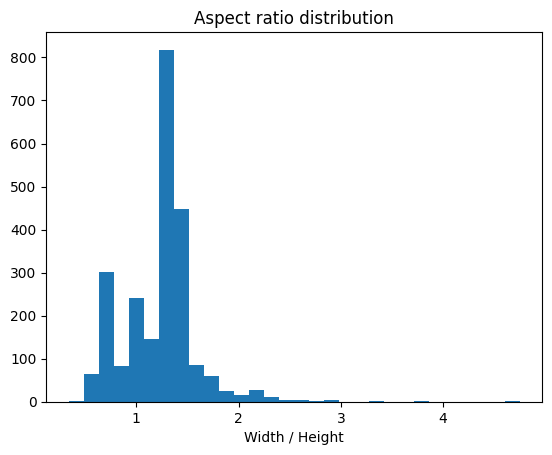

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

widths, heights = [], []

for class_name in final_classes:
    class_path = os.path.join(train_dir, class_name)
    for img_name in os.listdir(class_path):
        try:
            img = Image.open(os.path.join(class_path, img_name))
            w, h = img.size
            widths.append(w)
            heights.append(h)
        except:
            pass  # already caught in corruption check above

widths, heights = np.array(widths), np.array(heights)
aspect_ratios = widths / heights

print(f"Width  - min: {widths.min()}, max: {widths.max()}, mean: {widths.mean():.0f}")
print(f"Height - min: {heights.min()}, max: {heights.max()}, mean: {heights.mean():.0f}")
print(f"Aspect ratio - min: {aspect_ratios.min():.2f}, max: {aspect_ratios.max():.2f}, mean: {aspect_ratios.mean():.2f}")

plt.hist(aspect_ratios, bins=30)
plt.title("Aspect ratio distribution")
plt.xlabel("Width / Height")
plt.show()

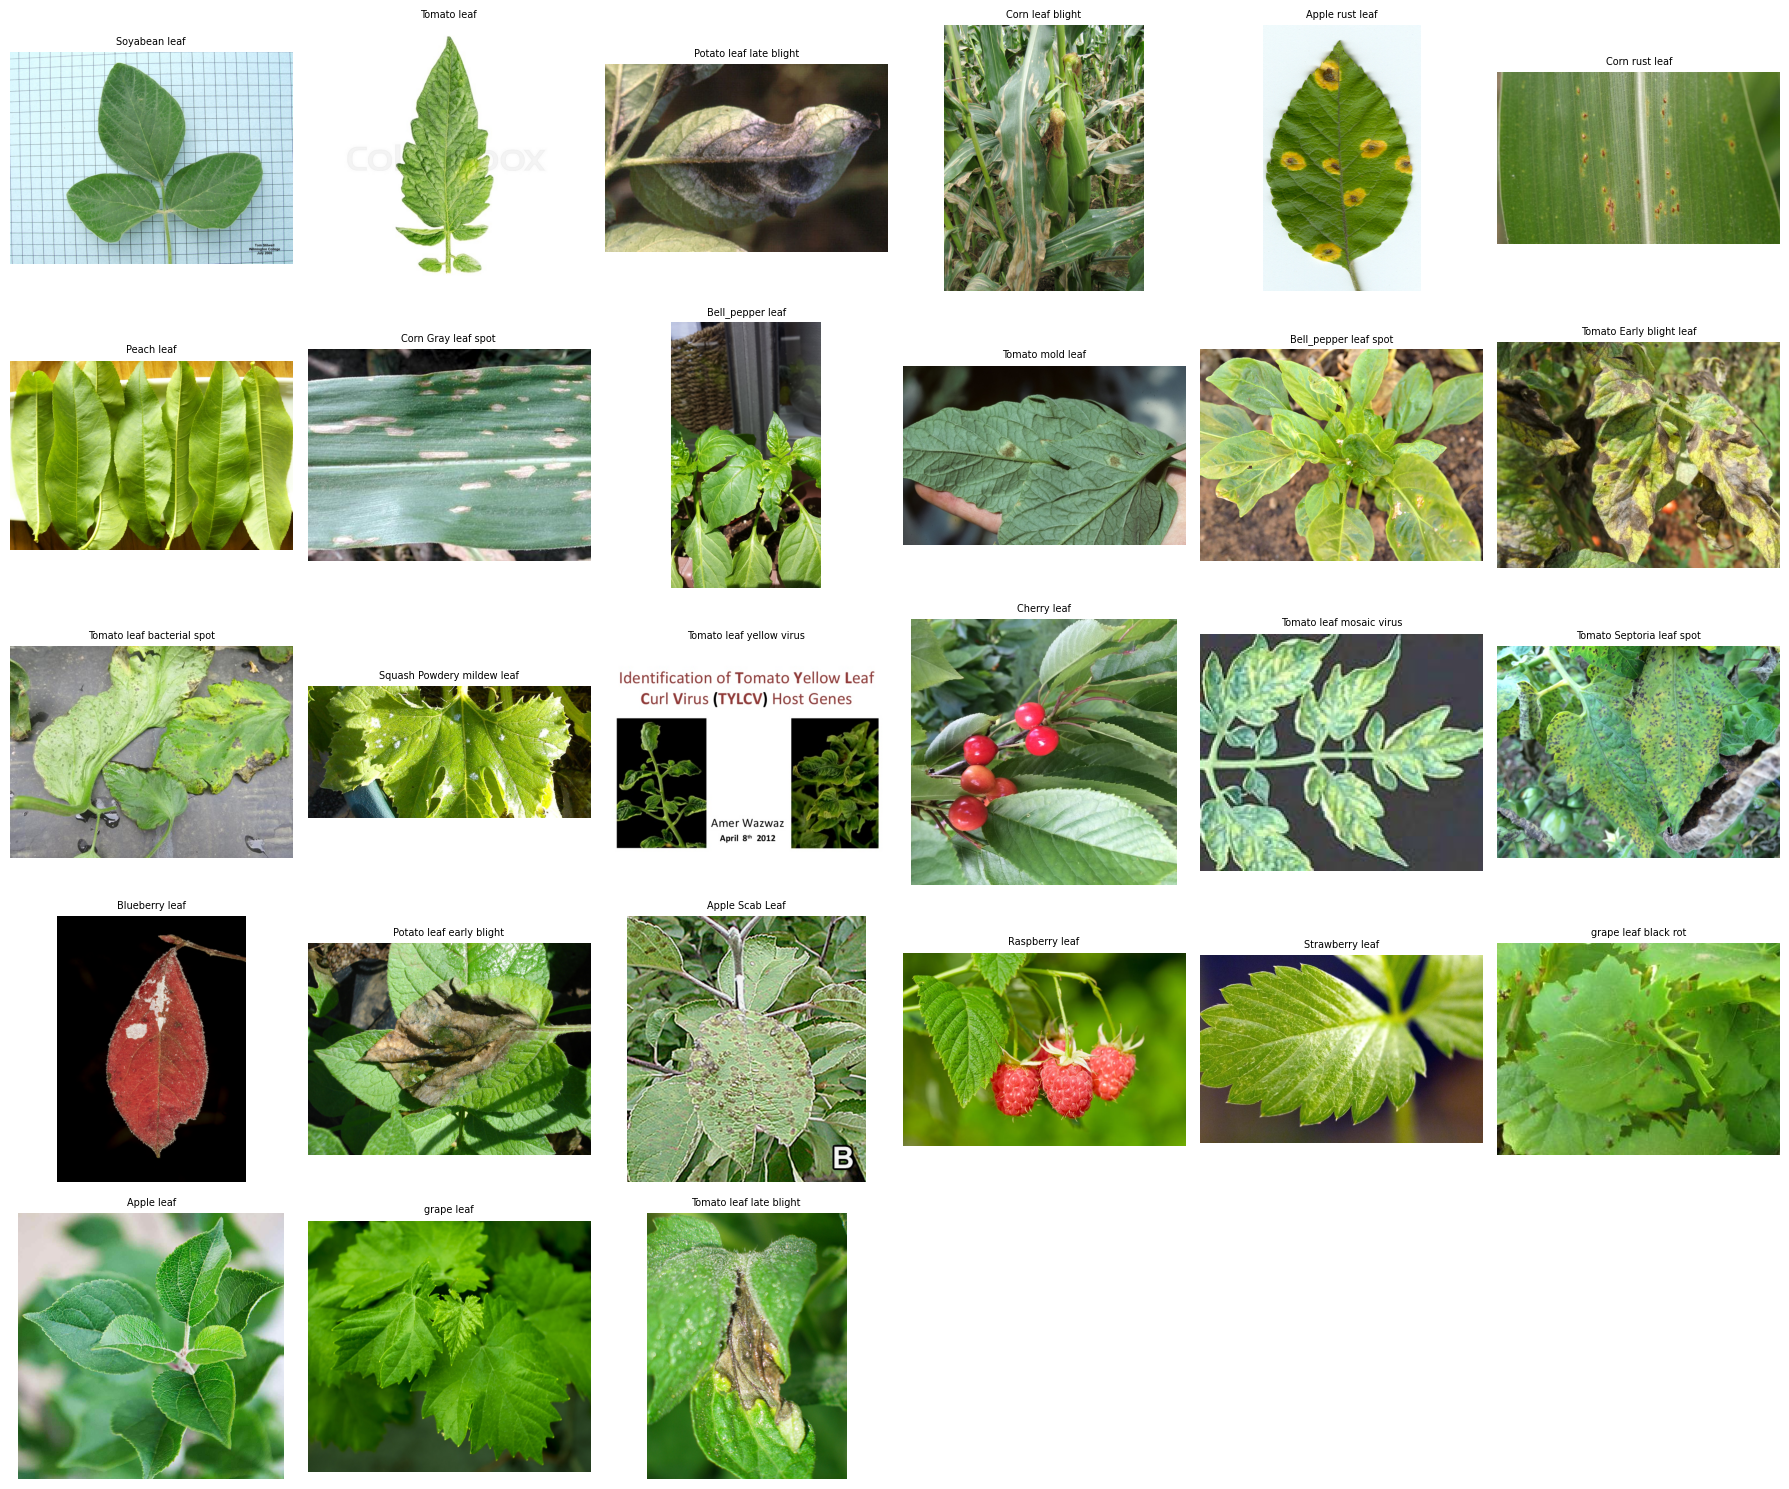

In [ ]:
n_classes = len(final_classes)
cols = 6
rows = (n_classes // cols) + 1

fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 3))
axes = axes.flatten()

for i, class_name in enumerate(final_classes):
    class_path = os.path.join(train_dir, class_name)
    img_name = os.listdir(class_path)[0]
    img = Image.open(os.path.join(class_path, img_name))
    axes[i].imshow(img)
    axes[i].set_title(class_name, fontsize=7)
    axes[i].axis('off')

for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

labels = []
for i, class_name in enumerate(final_classes):
    labels += [i] * class_counts[class_name]

class_weights = compute_class_weight('balanced', classes=np.arange(len(final_classes)), y=labels)
print(dict(zip(final_classes, class_weights.round(2))))

{'Soyabean leaf': np.float64(1.52), 'Tomato leaf': np.float64(1.58), 'Potato leaf late blight': np.float64(0.89), 'Corn leaf blight': np.float64(0.48), 'Apple rust leaf': np.float64(1.1), 'Corn rust leaf': np.float64(0.82), 'Peach leaf': np.float64(0.84), 'Corn Gray leaf spot': np.float64(1.35), 'Bell_pepper leaf': np.float64(1.64), 'Tomato mold leaf': np.float64(1.02), 'Bell_pepper leaf spot': np.float64(1.4), 'Tomato Early blight leaf': np.float64(1.1), 'Tomato leaf bacterial spot': np.float64(0.86), 'Squash Powdery mildew leaf': np.float64(0.7), 'Tomato leaf yellow virus': np.float64(1.24), 'Cherry leaf': np.float64(1.84), 'Tomato leaf mosaic virus': np.float64(1.97), 'Tomato Septoria leaf spot': np.float64(0.62), 'Blueberry leaf': np.float64(0.82), 'Potato leaf early blight': np.float64(0.8), 'Apple Scab Leaf': np.float64(1.04), 'Raspberry leaf': np.float64(0.77), 'Strawberry leaf': np.float64(0.98), 'grape leaf black rot': np.float64(1.55), 'Apple leaf': np.float64(1.06), 'grape l

In [ ]:
import os

train_dir = "PlantDoc-Dataset/train"

# print every class name so you can manually categorize accurately
for i, class_name in enumerate(sorted(final_classes)):
    print(f"{i}: {class_name}")

0: Apple Scab Leaf
1: Apple leaf
2: Apple rust leaf
3: Bell_pepper leaf
4: Bell_pepper leaf spot
5: Blueberry leaf
6: Cherry leaf
7: Corn Gray leaf spot
8: Corn leaf blight
9: Corn rust leaf
10: Peach leaf
11: Potato leaf early blight
12: Potato leaf late blight
13: Raspberry leaf
14: Soyabean leaf
15: Squash Powdery mildew leaf
16: Strawberry leaf
17: Tomato Early blight leaf
18: Tomato Septoria leaf spot
19: Tomato leaf
20: Tomato leaf bacterial spot
21: Tomato leaf late blight
22: Tomato leaf mosaic virus
23: Tomato leaf yellow virus
24: Tomato mold leaf
25: grape leaf
26: grape leaf black rot


In [ ]:
healthy_classes = [
    "Apple leaf",
    "grape leaf",
    "Tomato leaf",
    "Cherry leaf",
    "Blueberry leaf",
    "Soyabean leaf",
    "Raspberry leaf",
    "Strawberry leaf",
    "Bell_pepper leaf",
    "Peach leaf",

]

healthy_count = 0
diseased_count = 0
healthy_breakdown = {}
diseased_breakdown = {}

for class_name in final_classes:
    count = class_counts[class_name]
    if class_name in healthy_classes:
        healthy_count += count
        healthy_breakdown[class_name] = count
    else:
        diseased_count += count
        diseased_breakdown[class_name] = count

print(f"Healthy images: {healthy_count}")
print(f"Diseased images: {diseased_count}")
print(f"Healthy ratio: {healthy_count / (healthy_count + diseased_count):.2%}")

print("\nHealthy classes used:")
for k, v in healthy_breakdown.items():
    print(f"  {k}: {v}")

print("\nDiseased classes used:")
for k, v in diseased_breakdown.items():
    print(f"  {k}: {v}")

Healthy images: 760
Diseased images: 1580
Healthy ratio: 32.48%

Healthy classes used:
  Soyabean leaf: 57
  Tomato leaf: 55
  Peach leaf: 103
  Bell_pepper leaf: 53
  Cherry leaf: 47
  Blueberry leaf: 106
  Raspberry leaf: 112
  Strawberry leaf: 88
  Apple leaf: 82
  grape leaf: 57

Diseased classes used:
  Potato leaf late blight: 97
  Corn leaf blight: 180
  Apple rust leaf: 79
  Corn rust leaf: 106
  Corn Gray leaf spot: 64
  Tomato mold leaf: 85
  Bell_pepper leaf spot: 62
  Tomato Early blight leaf: 79
  Tomato leaf bacterial spot: 101
  Squash Powdery mildew leaf: 124
  Tomato leaf yellow virus: 70
  Tomato leaf mosaic virus: 44
  Tomato Septoria leaf spot: 140
  Potato leaf early blight: 109
  Apple Scab Leaf: 83
  grape leaf black rot: 56
  Tomato leaf late blight: 101


In [ ]:
import torch
import torch.nn as nn
from torchvision import transforms, datasets, models
from torch.utils.data import DataLoader, random_split

In [ ]:
# Training transforms - includes augmentation since our dataset is small
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation transforms - NO augmentation, only resize + normalize
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
full_dataset = datasets.ImageFolder(root=train_dir, transform=train_transform)

# ImageFolder auto-includes ALL folders - filter down to only your final_classes
class_to_idx = full_dataset.class_to_idx
valid_indices = [i for i, (path, label) in enumerate(full_dataset.samples)
                  if full_dataset.classes[label] in final_classes]

print(f"Total images before filtering: {len(full_dataset)}")
print(f"Total images after filtering to final_classes: {len(valid_indices)}")

Total images before filtering: 2342
Total images after filtering to final_classes: 2340


In [ ]:
from torch.utils.data import Subset

# Use the filtered indices from Step 2
filtered_dataset = Subset(full_dataset, valid_indices)

# 80/20 train/validation split
train_size = int(0.8 * len(filtered_dataset))
val_size = len(filtered_dataset) - train_size
train_dataset, val_dataset = random_split(filtered_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Training images: {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")

Training images: 1872
Validation images: 468


In [ ]:
model = models.resnet18(pretrained=True)

# Freeze all pretrained layers first (we'll only train the final layer initially)
for param in model.parameters():
    param.requires_grad = False

# Replace the final classification layer to match YOUR number of classes
num_classes = len(final_classes)
model.fc = nn.Linear(model.fc.in_features, num_classes)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(f"Using device: {device}")
print(f"Number of output classes: {num_classes}")

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 185MB/s]


Using device: cuda
Number of output classes: 27


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get labels for the training subset only
train_labels = [filtered_dataset[i][1] for i in train_dataset.indices]

class_weights = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

In [ ]:
# Build a clean mapping: old ImageFolder index -> new 0-based index for only final_classes
final_classes_sorted = sorted(final_classes)
old_to_new_label = {}

for old_idx, class_name in enumerate(full_dataset.classes):
    if class_name in final_classes_sorted:
        old_to_new_label[old_idx] = final_classes_sorted.index(class_name)

print(old_to_new_label)  # sanity check - should map old indices to a clean 0..N-1 range

{0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11, 12: 12, 13: 13, 14: 14, 15: 15, 16: 16, 17: 17, 18: 18, 19: 19, 20: 20, 21: 21, 22: 22, 23: 23, 24: 24, 26: 25, 27: 26}


In [ ]:
from torch.utils.data import Dataset

class RemappedDataset(Dataset):
    def __init__(self, base_dataset, indices, label_map):
        self.base_dataset = base_dataset
        self.indices = indices
        self.label_map = label_map

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        image, old_label = self.base_dataset[real_idx]
        new_label = self.label_map[old_label]
        return image, new_label

filtered_dataset = RemappedDataset(full_dataset, valid_indices, old_to_new_label)

In [ ]:
train_size = int(0.8 * len(filtered_dataset))
val_size = len(filtered_dataset) - train_size
train_dataset, val_dataset = random_split(filtered_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [ ]:
num_epochs = 40

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{num_epochs} - Training loss: {avg_loss:.4f}")

Epoch 1/40 - Training loss: 1.4511
Epoch 2/40 - Training loss: 0.9423
Epoch 3/40 - Training loss: 0.7082
Epoch 4/40 - Training loss: 0.5530
Epoch 5/40 - Training loss: 0.4205
Epoch 6/40 - Training loss: 0.3293
Epoch 7/40 - Training loss: 0.2538
Epoch 8/40 - Training loss: 0.2166
Epoch 9/40 - Training loss: 0.1819
Epoch 10/40 - Training loss: 0.1478
Epoch 11/40 - Training loss: 0.1381
Epoch 12/40 - Training loss: 0.1114
Epoch 13/40 - Training loss: 0.1060
Epoch 14/40 - Training loss: 0.0906
Epoch 15/40 - Training loss: 0.0987
Epoch 16/40 - Training loss: 0.0791
Epoch 17/40 - Training loss: 0.1017
Epoch 18/40 - Training loss: 0.0788
Epoch 19/40 - Training loss: 0.0683
Epoch 20/40 - Training loss: 0.0576
Epoch 21/40 - Training loss: 0.0784
Epoch 22/40 - Training loss: 0.0571
Epoch 23/40 - Training loss: 0.0440
Epoch 24/40 - Training loss: 0.0548
Epoch 25/40 - Training loss: 0.0665
Epoch 26/40 - Training loss: 0.0499
Epoch 27/40 - Training loss: 0.0548
Epoch 28/40 - Training loss: 0.0472
E

In [ ]:
for param in model.layer4.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam([
    {'params': model.fc.parameters(), 'lr': 0.001},
    {'params': model.layer4.parameters(), 'lr': 0.0001}
])

In [ ]:
from sklearn.metrics import classification_report, f1_score

model.eval()  # switches off dropout/batchnorm training behavior
all_preds = []
all_labels = []

with torch.no_grad():  # disables gradient tracking - faster, and correct for evaluation
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=sorted(final_classes)))
print(f"\nOverall F1 (macro): {f1_score(all_labels, all_preds, average='macro'):.4f}")

                            precision    recall  f1-score   support

           Apple Scab Leaf       0.55      0.40      0.46        15
                Apple leaf       0.73      0.61      0.67        18
           Apple rust leaf       0.71      0.71      0.71        21
          Bell_pepper leaf       0.56      0.56      0.56         9
     Bell_pepper leaf spot       0.40      0.17      0.24        12
            Blueberry leaf       0.67      0.56      0.61        25
               Cherry leaf       0.53      0.75      0.62        12
       Corn Gray leaf spot       0.60      0.46      0.52        13
          Corn leaf blight       0.74      0.78      0.76        36
            Corn rust leaf       0.66      0.83      0.73        23
                Peach leaf       0.62      0.88      0.73        17
  Potato leaf early blight       0.45      0.38      0.42        26
   Potato leaf late blight       0.60      0.16      0.25        19
            Raspberry leaf       0.67      0.62